# Comb identification -- validation on synthetic COS spectra

Goal: check that `detect.identify` finds the absorption systems of a
quasar spectrum and names their lines, before running it on 3C 273.

Method of `identify` (details in `spectral_diag/detect/identify.py`): each
species is a "comb" of lines whose wavelength ratios never change. Each
detected feature is tried as each line of each comb, which gives a
candidate velocity; the comb placed there is accepted if at least 3 of its
lines land on features (within 15 km/s), with consistent strengths (EW
ratios between the f-lambda ratio and 1), and no stronger line missing where
there is data. The best comb sets a system velocity; every species is then
labelled at that velocity (within 10 km/s), single-line species included.

Test spectra: HST/COS G130M-like (1142-1444 Angstrom, detector gap
1289-1298 Angstrom, FWHM 16 km/s, S/N 20 per pixel), with

- a Milky-Way-like absorber at -12 km/s (CII, NI, OI, SiII, SiIII, SiIV, SII, FeII),
- a weaker high-velocity cloud at -150 km/s (CII, SiII, SiIII, SiIV),
- 30 unrelated lines at random wavelengths, standing in for the
  intergalactic Lyman-alpha lines of a real quasar.

The continuum is known (= 1): we assume a proper continuum, as Pablo's
quasar continuum should give. Wavelengths in Angstrom (vacuum),
velocities in km/s.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np

from spectral_diag import constants
from spectral_diag.data_classes import Absorber, Line, Spectrum
from spectral_diag.detect import CombSettings, find_features, identify
from spectral_diag.line_list import LineSelection, get_lines
from spectral_diag.line_profiles import InstrumentGrid, optical_depth

# HST/COS G130M at central wavelength 1291 A
WAVE_MIN, WAVE_MAX = 1142.0, 1444.0
DETECTOR_GAP = (1289.0, 1298.0)
# Pixel width in log10(wave): 0.01 A at 1300 A
PIXEL_DEX = 3.34e-6
FWHM_KMS = 16.0
OVERSAMPLE = 10
SNR = 20.0
DETECTION_THRESHOLD = 5.0

# log10 N (cm^-2) of each species in each absorber
MILKY_WAY = {"CII": 15.5, "NI": 14.8, "OI": 15.8, "SiII": 15.0, "SiIII": 13.5,
             "SiIV": 13.3, "SII": 15.2, "FeII": 14.7}
MILKY_WAY_VELOCITY, MILKY_WAY_B = -12.0, 15.0
HIGH_VELOCITY_CLOUD = {"CII": 14.0, "SiII": 13.3, "SiIII": 13.0, "SiIV": 12.9}
HIGH_VELOCITY, HIGH_VELOCITY_B = -150.0, 12.0
N_UNRELATED = 30

# Species given to identify (HI, CI, NV are tried but not injected)
SPECIES = ["HI", "CI", "CII", "NI", "NV", "OI", "SiII", "SiIII", "SiIV", "SII", "FeII"]
# A system found within this distance of a true one is that system
SAME_SYSTEM_KMS = 20.0

## 1. Synthetic spectrum

The lines are computed on a grid finer than the pixels, convolved with the
line spread function and averaged over each pixel (`InstrumentGrid`), then
noise is added and the pixels of the detector gap are removed.

In [2]:
def absorbers_of(log_columns, velocity, b):
    # One Absorber per species, with all its lines from NIST (f >= 1e-3)
    z = velocity / constants.C_KMS
    absorbers = []
    for species, log_column in log_columns.items():
        lines = get_lines(species, LineSelection(1100, 1500, f_min=1e-3))
        absorbers.append(Absorber(species, z, log_column, b, lines))
    return absorbers


def unrelated_absorbers(rng, n_lines):
    # Single lines of an unknown species "X" at random wavelengths
    absorbers = []
    for _ in range(n_lines):
        line = Line("X", rng.uniform(WAVE_MIN, WAVE_MAX), 0.1, 1e8)
        log_column = rng.uniform(12.8, 13.8)
        b = rng.uniform(10, 30)
        absorbers.append(Absorber("X", 0.0, log_column, b, [line]))
    return absorbers


def test_absorbers(rng):
    # The two systems and the unrelated lines
    return (absorbers_of(MILKY_WAY, MILKY_WAY_VELOCITY, MILKY_WAY_B)
            + absorbers_of(HIGH_VELOCITY_CLOUD, HIGH_VELOCITY, HIGH_VELOCITY_B)
            + unrelated_absorbers(rng, N_UNRELATED))


def cos_like_spectrum(absorbers, rng):
    # Normalised COS-like spectrum (continuum = 1) of the absorbers, with noise
    n_pixels = int(np.log10(WAVE_MAX / WAVE_MIN) / PIXEL_DEX)
    wave = WAVE_MIN * 10 ** (PIXEL_DEX * np.arange(n_pixels))
    meta = {"pixel_dex": PIXEL_DEX, "fwhm_kms": FWHM_KMS}
    template = Spectrum(wave, np.ones_like(wave), np.ones_like(wave), meta=meta)
    grid = InstrumentGrid.for_spectrum(template, OVERSAMPLE)
    tau = np.zeros_like(grid.wave)
    for absorber in absorbers:
        for line in absorber.lines:
            tau += optical_depth(grid.wave, line, absorber.logN, absorber.b, absorber.z)
    error = np.full_like(wave, 1 / SNR)
    flux = grid.observe(np.exp(-tau)) + rng.normal(0, error)
    outside_gap = (wave < DETECTOR_GAP[0]) | (wave > DETECTOR_GAP[1])
    return Spectrum(wave[outside_gap], flux[outside_gap], error[outside_gap],
                    continuum=np.ones(outside_gap.sum()), meta=meta)


rng = np.random.default_rng(1)
absorbers = test_absorbers(rng)
spectrum = cos_like_spectrum(absorbers, rng)
print(f"{spectrum.wave.size} pixels, {spectrum.wave[0]:.1f}-{spectrum.wave[-1]:.1f} A")

29604 pixels, 1142.0-1444.0 A


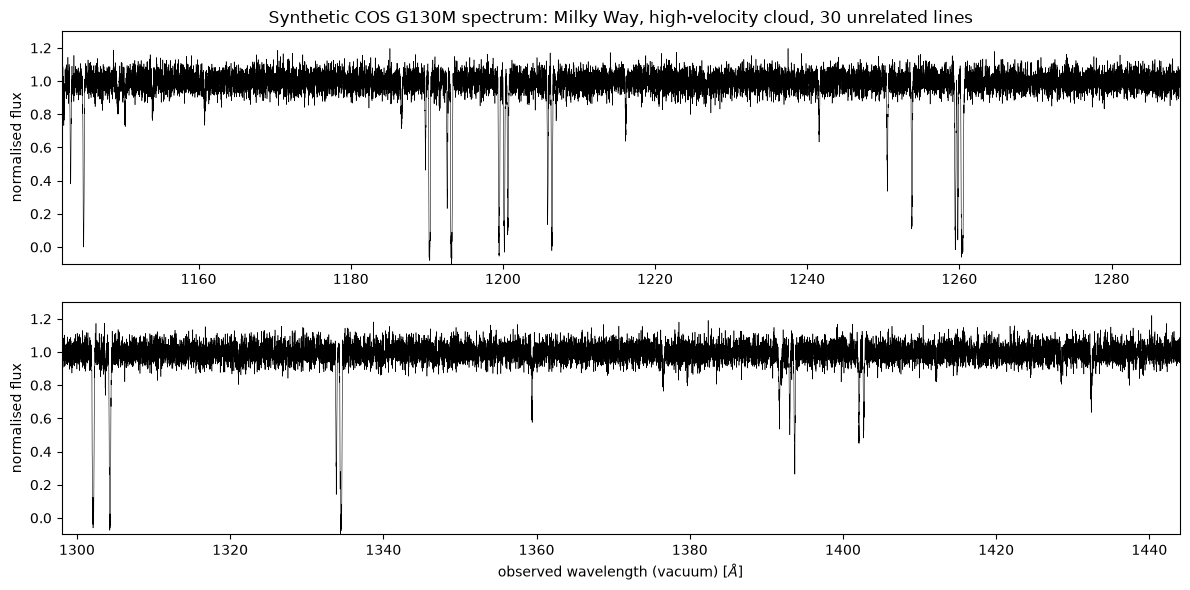

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
halves = [(WAVE_MIN, DETECTOR_GAP[0]), (DETECTOR_GAP[1], WAVE_MAX)]
for ax, (start, end) in zip(axes, halves):
    inside = (spectrum.wave >= start) & (spectrum.wave <= end)
    ax.plot(spectrum.wave[inside], spectrum.flux[inside], lw=0.4, color="k")
    ax.set_xlim(start, end)
    ax.set_ylim(-0.1, 1.3)
    ax.set_ylabel("normalised flux")
axes[1].set_xlabel(r"observed wavelength (vacuum) [$\AA$]")
axes[0].set_title("Synthetic COS G130M spectrum: Milky Way, high-velocity cloud, 30 unrelated lines")
plt.tight_layout()
plt.show()

## 2. Detection and identification

In [4]:
features = find_features(spectrum, threshold=DETECTION_THRESHOLD)
identified = identify(features, spectrum, SPECIES)

print(f"{len(features)} features detected at {DETECTION_THRESHOLD:.0f} sigma, "
      f"{np.sum(identified['line'] != '')} identified")
print("System velocities found (km/s):")
for velocity in identified.meta["systems"]:
    print(f"  {velocity:8.2f}")
print(f"True: {MILKY_WAY_VELOCITY} (Milky Way), {HIGH_VELOCITY} (high-velocity cloud)")
identified["wave", "wave_min", "wave_max", "ew", "species", "line", "v"].pprint_all()

45 features detected at 5 sigma, 25 identified
System velocities found (km/s):
   -149.99
    -11.20
True: -12.0 (Milky Way), -150.0 (high-velocity cloud)
  wave   wave_min wave_max   ew  species      line               v         
-------- -------- -------- ----- ------- -------------- -------------------
1142.324 1142.211 1142.448 0.024    FeII  FeII 1142.366 -11.052028638159584
1143.181 1143.028 1143.353 0.083    FeII  FeII 1143.226 -11.834312573816925
1144.892 1144.691 1145.078 0.160    FeII  FeII 1144.939 -12.373767196723605
1149.399 1149.127 1149.552 0.035                                        nan
1150.334 1150.082 1150.516 0.043                                        nan
1153.946 1153.830 1154.069 0.028                                        nan
1160.811 1160.683 1161.004 0.032                                        nan
1186.674 1186.458 1186.851 0.048                                        nan
1189.823 1189.693 1189.968 0.057    SiII  SiII 1190.416  -149.3443644834935
1190.368 

Blank rows are the unrelated lines (and a few weak features): they belong
to no comb, so they stay unidentified. A feature that holds two lines
(SiII 1260.42 and FeII 1260.54, 26 km/s apart, unresolved) gets one label,
the closest.

## 3. Score

Each feature is compared with the injected lines whose observed centre
falls in its window:

- **correct**: its label is one of those lines, at that line's velocity
  (within 20 km/s);
- **wrong**: labelled, but none of its lines has that name and velocity;
- **missed**: unlabelled, although it holds a line of one of the two
  systems.

In [5]:
def injected_lines(absorbers):
    # (observed wave, line name, velocity) of every injected line on data
    lines = []
    for absorber in absorbers:
        velocity = absorber.z * constants.C_KMS
        for line in absorber.lines:
            observed = line.wave_rest * (1 + absorber.z)
            on_data = WAVE_MIN < observed < WAVE_MAX
            in_gap = DETECTOR_GAP[0] < observed < DETECTOR_GAP[1]
            if on_data and not in_gap:
                lines.append((observed, line.name, velocity))
    return lines


def score(identified, absorbers):
    # Number of correct, wrong and missed features
    lines = injected_lines(absorbers)
    counts = {"correct": 0, "wrong": 0, "missed": 0}
    for row in identified:
        in_window = []
        for wave, name, velocity in lines:
            if row["wave_min"] <= wave <= row["wave_max"] and name[0] != "X":
                in_window.append((name, velocity))
        if row["line"]:
            matches = [name == row["line"] and abs(velocity - row["v"]) < SAME_SYSTEM_KMS
                       for name, velocity in in_window]
            counts["correct" if any(matches) else "wrong"] += 1
        elif in_window:
            counts["missed"] += 1
    return counts


counts = score(identified, absorbers)
print(counts)
velocities = sorted(identified.meta["systems"])
assert len(velocities) == 2
assert abs(velocities[0] - HIGH_VELOCITY) < 2 and abs(velocities[1] - MILKY_WAY_VELOCITY) < 2
assert counts["wrong"] == 0
print("PASS: both systems found within 2 km/s, no wrong label.")

{'correct': 25, 'wrong': 0, 'missed': 1}
PASS: both systems found within 2 km/s, no wrong label.


## 4. Labelled spectrum

Labels of the Milky Way in blue, of the high-velocity cloud in red; the
unrelated lines stay unlabelled.

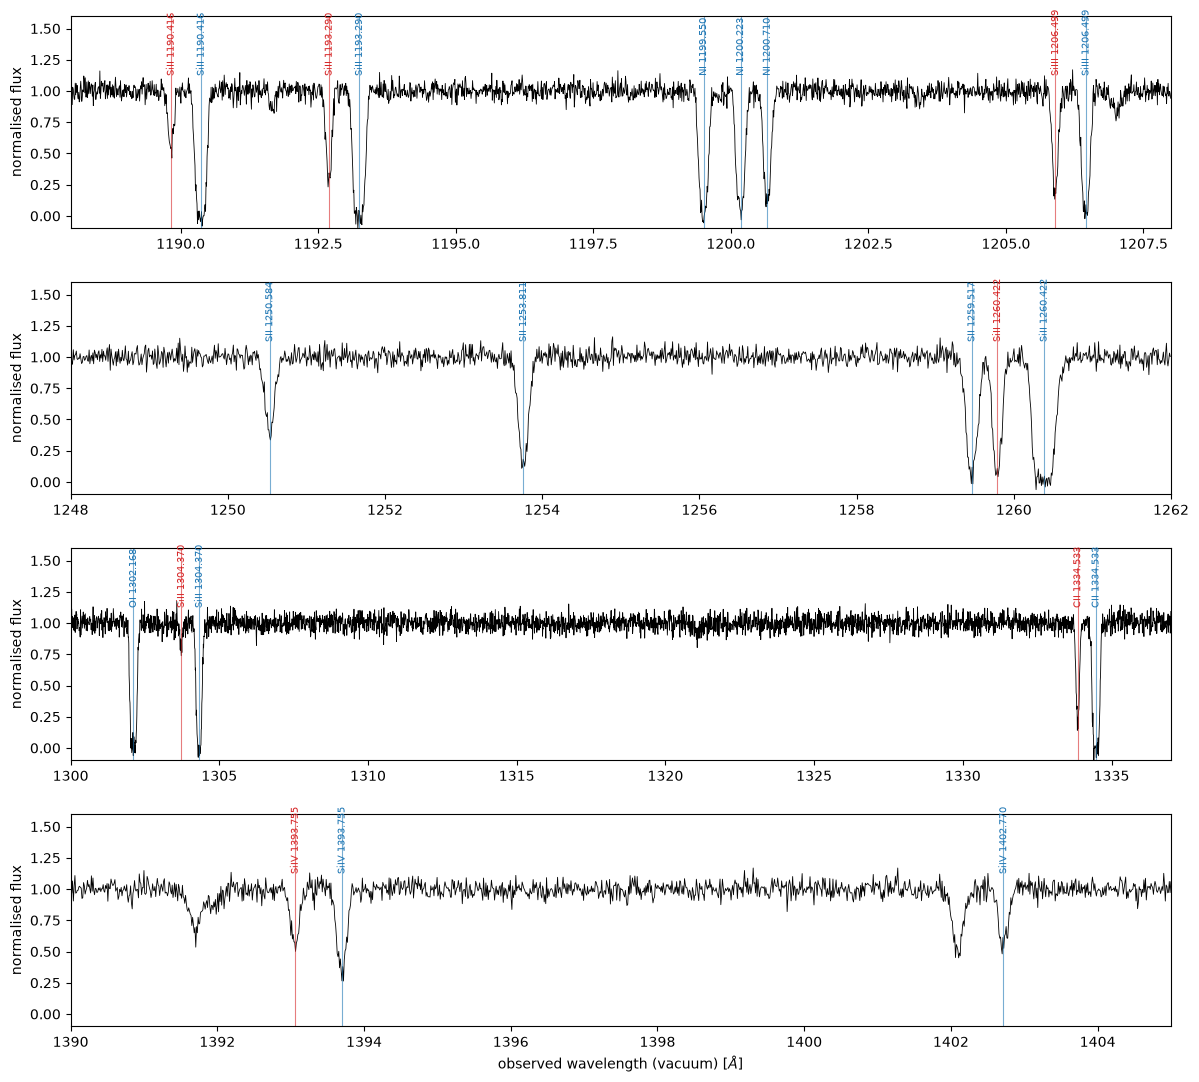

In [6]:
ZOOMS = [(1188.0, 1208.0), (1248.0, 1262.0), (1300.0, 1337.0), (1390.0, 1405.0)]


def plot_labelled(ax, spectrum, identified, start, end):
    # Normalised flux with the line name above each identified feature
    inside = (spectrum.wave >= start) & (spectrum.wave <= end)
    ax.plot(spectrum.wave[inside], spectrum.flux[inside], lw=0.6, color="k")
    for row in identified:
        if not row["line"] or not start <= row["wave"] <= end:
            continue
        color = "C3" if row["v"] < -80 else "C0"
        ax.axvline(row["wave"], color=color, lw=0.8, alpha=0.6)
        ax.text(row["wave"], 1.12, row["line"], rotation=90, fontsize=7,
                color=color, ha="center", va="bottom")
    ax.set_xlim(start, end)
    ax.set_ylim(-0.1, 1.6)


fig, axes = plt.subplots(len(ZOOMS), 1, figsize=(12, 11))
for ax, (start, end) in zip(axes, ZOOMS):
    plot_labelled(ax, spectrum, identified, start, end)
    ax.set_ylabel("normalised flux")
axes[-1].set_xlabel(r"observed wavelength (vacuum) [$\AA$]")
plt.tight_layout()
plt.show()

## 5. Many realisations

30 spectra, each with new noise and new unrelated lines. For each, the
systems found are compared with the two true ones; a system more than
20 km/s from both is a false system. The default settings (3 lines needed
to define a system) are compared with `min_teeth=2`.

In [7]:
N_REALISATIONS = 30


def run_realisations(settings):
    # Totals of correct, wrong and missed features, false systems, velocity errors
    totals = {"correct": 0, "wrong": 0, "missed": 0}
    false_systems = 0
    velocity_errors = []
    for seed in range(N_REALISATIONS):
        rng = np.random.default_rng(100 + seed)
        absorbers = test_absorbers(rng)
        spectrum = cos_like_spectrum(absorbers, rng)
        identified = identify(find_features(spectrum, threshold=DETECTION_THRESHOLD),
                              spectrum, SPECIES, settings)
        for key, count in score(identified, absorbers).items():
            totals[key] += count
        for velocity in identified.meta["systems"]:
            error = min(velocity - MILKY_WAY_VELOCITY, velocity - HIGH_VELOCITY, key=abs)
            if abs(error) < SAME_SYSTEM_KMS:
                velocity_errors.append(error)
            else:
                false_systems += 1
    return totals, false_systems, np.array(velocity_errors)


results = {}
for name, settings in [("default (3 lines)", CombSettings()),
                       ("min_teeth=2", CombSettings(min_teeth=2))]:
    results[name] = run_realisations(settings)
    totals, false_systems, velocity_errors = results[name]
    print(f"{name:18s}: {totals}, false systems {false_systems}, "
          f"true systems found {velocity_errors.size}/{2 * N_REALISATIONS}, "
          f"velocity error {velocity_errors.mean():+.2f} +- {velocity_errors.std():.2f} km/s")

default (3 lines) : {'correct': 776, 'wrong': 7, 'missed': 4}, false systems 0, true systems found 60/60, velocity error +0.23 +- 0.74 km/s
min_teeth=2       : {'correct': 776, 'wrong': 9, 'missed': 4}, false systems 1, true systems found 60/60, velocity error +0.23 +- 0.74 km/s


In [8]:
totals, false_systems, velocity_errors = results["default (3 lines)"]
labelled = totals["correct"] + totals["wrong"]
assert velocity_errors.size == 2 * N_REALISATIONS
assert false_systems == 0
assert abs(velocity_errors.mean()) < 1 and velocity_errors.std() < 1
assert totals["wrong"] < 0.02 * labelled
assert totals["missed"] < 0.02 * (totals["correct"] + totals["missed"])
print("PASS: every system found within 1 km/s, no false system, "
      "less than 2% wrong labels and less than 2% missed lines.")

PASS: every system found within 1 km/s, no false system, less than 2% wrong labels and less than 2% missed lines.


## 6. What this does not test

- **The continuum.** It is known here (= 1). On 3C 273 the current spline
  gives many spurious features; `identify` needs Pablo's quasar continuum.
- **Real velocity structure.** Each system has one component with one
  velocity for all its species. In real Milky Way gas the high ions
  (SiIV, CIV) can sit 10-20 km/s from the low ions (SiII, SII) and be
  left unlabelled at the 10 km/s labelling tolerance.
- **Blends.** Two lines in one feature get one label (the closest); the EW
  of such a feature includes both lines and must not go into the curve of
  growth as it is.
- **Single-line species alone.** CII, OI, SiIII (and Lyalpha) are only
  identified at a velocity set by a species with 3 or more lines.